# Validação Volumétrica LiDAR — Dataset Canoas

Este notebook apresenta os objetivos, resultados e implicações técnicas dos quatro experimentos de validação volumétrica conduzidos sobre os talhões de *Eucalyptus* da fazenda Canoas (`T37`, `T62` e `T63`), comparando lado a lado dois critérios de calibração:
- **Mode 1A (Tree-RMSE Calibrated):** seleciona a configuração que minimiza o RMSE individual por árvore nas parcelas de treino.
- **Mode 1B (Plot-Bias Calibrated):** seleciona a configuração que minimiza o viés relativo médio (`|bias_pct|`) dentro da faixa de RMSE estável.
- **Mode 2 (Human-in-the-Loop / Oracle):** limite superior teórico obtido selecionando a melhor configuração por árvore.

### Estrutura dos Experimentos
1. **Experimento 1 (Talhão 37 — 10cm):** Validação cruzada *Leave-One-Plot-Out* (LOPO) em 11 parcelas e curva de saturação amostral ($N = 2, 4, 6, 8, 10$ parcelas de treino).
2. **Experimento 2 (Talhão 62 $\to$ Talhão 63 — 5cm):** Transferibilidade intra-clone entre blocos adjacentes e impacto da sobreposição de faixas de voo na densidade de pontos.
3. **Experimento 3 (Talhão 62 — 5cm vs. 10cm):** Comparação direta entre resoluções de voo nas mesmas 4 parcelas de campo com segmentação independente pelo ForestFormer3D.
4. **Experimento 4 (T37 10cm $\leftrightarrow$ T62 10cm vs. 5cm):** Transferibilidade entre talhões quando a resolução espacial da nuvem é pareada em 10cm versus quando há diferença de resolução.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid')

RESULTS_DIR = os.path.abspath('../results')
print('Diretório de resultados:', RESULTS_DIR)

Diretório de resultados: /home/matheuspimenta/euc/projeto_eucalipto/research/volume_validation/results


--- 
## Experimento 1: Validação Cruzada (LOPO) e Curva de Saturação no Talhão 37 (10cm)

### Objetivo
- Avaliar a capacidade de generalização da estimativa de volume em parcelas não vistas durante a calibração (*Leave-One-Plot-Out* em 11 parcelas, totalizando 118 árvores pareadas com o inventário).
- Comparar a calibração por RMSE individual (**Mode 1A**) com a calibração por viés estável (**Mode 1B**) e verificar como o erro em parcelas de teste evolui conforme variamos a quantidade de parcelas de treino ($N \in \{2, 4, 6, 8, 10\}$).

In [2]:
df_lopo = pd.read_csv(os.path.join(RESULTS_DIR, 'exp1_t37/lopo_results_t37.csv'))
df_sat = pd.read_csv(os.path.join(RESULTS_DIR, 'exp1_t37/sampling_saturation_summary.csv'))

print('=== Resumo LOPO (11 Parcelas — Talhão 37, 10cm) ===')
print(f"Erro Absoluto Médio — Mode 1A (Tree-RMSE Cal): {df_lopo['err_global_ha_pct'].abs().mean():.2f}% (Viés médio: {df_lopo['err_global_ha_pct'].mean():+.2f}%)")
print(f"Erro Absoluto Médio — Mode 1B (Plot-Bias Cal): {df_lopo['err_bias_cal_ha_pct'].abs().mean():.2f}% (Viés médio: {df_lopo['err_bias_cal_ha_pct'].mean():+.2f}%)")
print(f"Erro Absoluto Médio — Mode 2  (Human Oracle) : {df_lopo['err_human_ha_pct'].abs().mean():.2f}% (Viés médio: {df_lopo['err_human_ha_pct'].mean():+.2f}%)")
display(df_lopo[['test_plot_id', 'n_test_trees', 'calibrated_config', 'calibrated_bias_config', 'gt_m3_ha', 'pred_global_m3_ha', 'err_global_ha_pct', 'pred_bias_cal_m3_ha', 'err_bias_cal_ha_pct', 'pred_human_m3_ha', 'err_human_ha_pct']].round(2))

=== Resumo LOPO (11 Parcelas — Talhão 37, 10cm) ===
Erro Absoluto Médio — Mode 1A (Tree-RMSE Cal): 34.38% (Viés médio: -33.81%)
Erro Absoluto Médio — Mode 1B (Plot-Bias Cal): 22.61% (Viés médio: -8.24%)
Erro Absoluto Médio — Mode 2  (Human Oracle) : 22.40% (Viés médio: -22.40%)


,test_plot_id,n_test_trees,calibrated_config,calibrated_bias_config,gt_m3_ha,pred_global_m3_ha,err_global_ha_pct,pred_bias_cal_m3_ha,err_bias_cal_ha_pct,pred_human_m3_ha,err_human_ha_pct
0,594,10,voxel_vs0.08,voxel_vs0.09,193.95,98.71,-49.10,141.08,-27.26,142.29,-26.64
1,602,10,voxel_vs0.08,voxel_vs0.09,192.89,67.83,-64.84,94.68,-50.92,125.85,-34.76
2,611,16,voxel_vs0.08,voxel_vs0.09,202.06,165.05,-18.32,227.39,12.54,174.77,-13.50
3,612,8,voxel_vs0.08,voxel_vs0.09,195.82,112.61,-42.49,156.85,-19.90,123.45,-36.96
4,621,7,voxel_vs0.08,voxel_vs0.09,203.73,73.80,-63.78,104.01,-48.95,124.06,-39.11
5,622,9,voxel_vs0.08,voxel_vs0.09,190.92,130.28,-31.76,180.47,-5.47,149.56,-21.66
6,623,19,voxel_vs0.08,voxel_vs0.09,163.32,150.27,-7.99,208.75,27.82,154.55,-5.37
7,634,12,voxel_vs0.08,voxel_vs0.09,231.19,162.69,-29.63,226.54,-2.01,193.89,-16.13
8,635,7,voxel_vs0.08,voxel_vs0.09,180.28,185.93,3.13,250.00,38.67,171.40,-4.93
9,636,11,voxel_vs0.08,voxel_vs0.09,159.37,112.28,-29.55,155.19,-2.62,113.18,-28.98


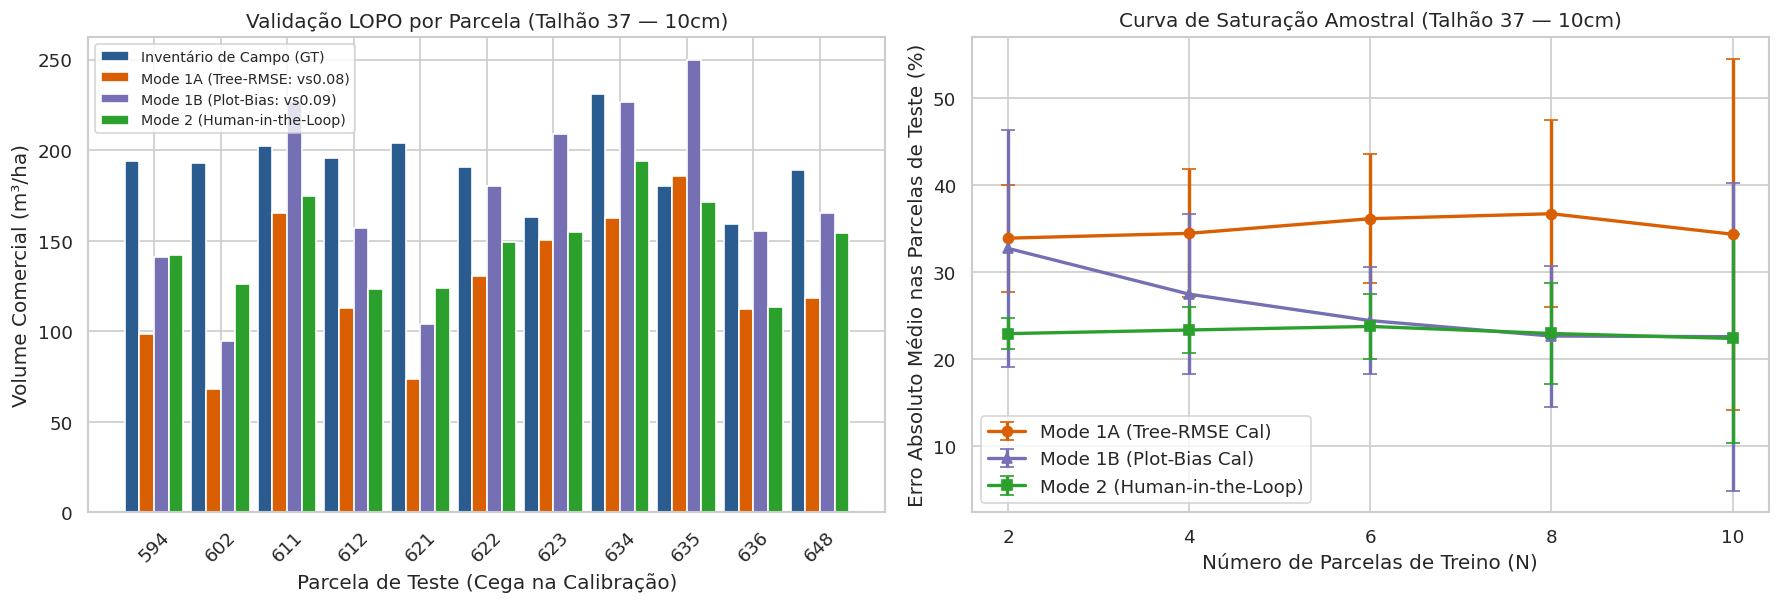

,n_train_plots,global_err_mean,global_err_std,bias_cal_err_mean,bias_cal_err_std,human_err_mean,human_err_std
0,2,33.92,6.16,32.75,13.62,22.96,1.78
1,4,34.48,7.34,27.49,9.18,23.37,2.70
2,6,36.16,7.40,24.45,6.10,23.78,3.68
3,8,36.73,10.73,22.68,8.09,22.97,5.83
4,10,34.38,20.17,22.61,17.69,22.40,11.98


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Painel A: LOPO por parcela
x = np.arange(len(df_lopo))
w = 0.22
axes[0].bar(x - 1.5*w, df_lopo['gt_m3_ha'], width=w, label='Inventário de Campo (GT)', color='#2b5c8f')
axes[0].bar(x - 0.5*w, df_lopo['pred_global_m3_ha'], width=w, label='Mode 1A (Tree-RMSE: vs0.08)', color='#d95f02')
axes[0].bar(x + 0.5*w, df_lopo['pred_bias_cal_m3_ha'], width=w, label='Mode 1B (Plot-Bias: vs0.09)', color='#7570b3')
axes[0].bar(x + 1.5*w, df_lopo['pred_human_m3_ha'], width=w, label='Mode 2 (Human-in-the-Loop)', color='#2ca02c')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_lopo['test_plot_id'].astype(str), rotation=45)
axes[0].set_xlabel('Parcela de Teste (Cega na Calibração)')
axes[0].set_ylabel('Volume Comercial (m³/ha)')
axes[0].set_title('Validação LOPO por Parcela (Talhão 37 — 10cm)')
axes[0].legend(frameon=True, fontsize=8.5)

# Painel B: Curva de Saturação
axes[1].errorbar(df_sat['n_train_plots'], df_sat['global_err_mean'], yerr=df_sat['global_err_std'],
                 fmt='-o', capsize=4, label='Mode 1A (Tree-RMSE Cal)', color='#d95f02', linewidth=2)
axes[1].errorbar(df_sat['n_train_plots'], df_sat['bias_cal_err_mean'], yerr=df_sat['bias_cal_err_std'],
                 fmt='-^', capsize=4, label='Mode 1B (Plot-Bias Cal)', color='#7570b3', linewidth=2)
axes[1].errorbar(df_sat['n_train_plots'], df_sat['human_err_mean'], yerr=df_sat['human_err_std'],
                 fmt='-s', capsize=4, label='Mode 2 (Human-in-the-Loop)', color='#2ca02c', linewidth=2)
axes[1].set_xlabel('Número de Parcelas de Treino (N)')
axes[1].set_ylabel('Erro Absoluto Médio nas Parcelas de Teste (%)')
axes[1].set_title('Curva de Saturação Amostral (Talhão 37 — 10cm)')
axes[1].set_xticks(df_sat['n_train_plots'])
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()
display(df_sat.round(2))

### Resultados e Implicações (Experimento 1)
- **Critério de Calibração (Tree-RMSE vs. Plot-Bias):** A minimização do RMSE individual por árvore (**Mode 1A**) seleciona `voxel_vs0.08` em todos os folds porque penaliza quadraticamente algumas árvores com vazamento de pontos de copa para o tronco; contudo, `voxel_vs0.08` subestima o volume médio em `-25,9%`, levando a um erro absoluto médio nas parcelas de **34,38%** (viés de `-33,81%`).
- Quando calibramos pelo menor viés relativo dentro da faixa de RMSE estável (**Mode 1B**, que seleciona `voxel_vs0.09`), o erro médio LOPO nas parcelas cai para **22,61%** (viés de `-8,24%`), praticamente empatando com o limite superior *Human-in-the-Loop* (**22,40%**).
- **Curva de Saturação Amostral:** Sob a calibração por viés (**Mode 1B**), o erro médio fora da amostra reduz-se monotonicamente conforme adicionamos parcelas de treino: **32,8%** ($N=2$) $\to$ **27,5%** ($N=4$) $\to$ **24,5%** ($N=6$) $\to$ **22,7%** ($N=8$) $\to$ **22,6%** ($N=10$), estabilizando entre 6 e 8 parcelas.

--- 
## Experimento 2: Transferibilidade Intra-Clone (Talhão 62 $\to$ Talhão 63 — 5cm)

### Objetivo
- Calibrar os modelos volumétricos nas 4 parcelas de campo do Talhão 62 (25,96 ha) e avaliar a extrapolação no Talhão 63 (15,04 ha, mesmo clone e idade, sem parcelas de campo anotadas na planilha oficial, compondo a unidade de manejo `062-063` com referência oficial de `201,29 m³/ha` e `650` árvores/ha).

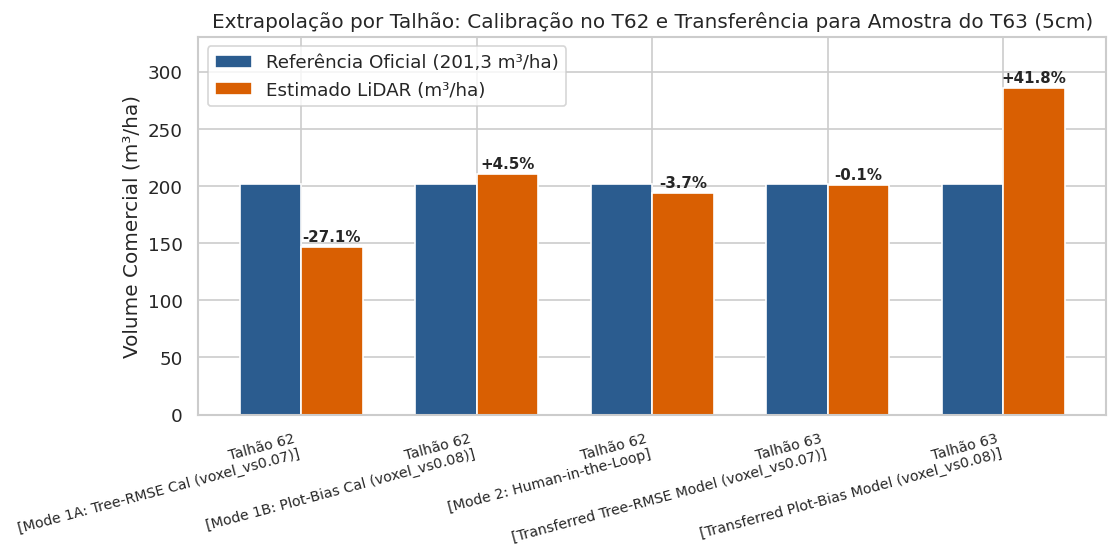

,stand,area_ha,mode,gt_m3_ha,pred_m3_ha,err_pct,gt_total_m3,pred_total_m3
0,Talhão 62 (Calibration Base),25.96,Mode 1A: Tree-RMSE Cal (voxel_vs0.07),201.29,146.77,-27.08,5225.49,3810.24
1,Talhão 62 (Calibration Base),25.96,Mode 1B: Plot-Bias Cal (voxel_vs0.08),201.29,210.40,4.52,5225.49,5461.88
2,Talhão 62 (Calibration Base),25.96,Mode 2: Human-in-the-Loop,201.29,193.85,-3.69,5225.49,5032.43
3,Talhão 63 (Transferred Blind Block),15.04,Transferred Tree-RMSE Model (voxel_vs0.07),201.29,201.14,-0.07,3027.40,3025.17
4,Talhão 63 (Transferred Blind Block),15.04,Transferred Plot-Bias Model (voxel_vs0.08),201.29,285.34,41.76,3027.40,4291.52


In [4]:
df_extrap = pd.read_csv(os.path.join(RESULTS_DIR, 'exp2_t62_t63/extrapolation_summary_t62_t63.csv'))
display(df_extrap.round(2))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
labels = [f"{r['stand'].split(' (')[0]}\n[{r['mode']}]" for _, r in df_extrap.iterrows()]
x = np.arange(len(labels))
w = 0.35

ax.bar(x - w/2, df_extrap['gt_m3_ha'], width=w, label='Referência Oficial (201,3 m³/ha)', color='#2b5c8f')
ax.bar(x + w/2, df_extrap['pred_m3_ha'], width=w, label='Estimado LiDAR (m³/ha)', color='#d95f02')
for i, r in df_extrap.iterrows():
    ax.text(i + w/2, r['pred_m3_ha'] + 5, f"{r['err_pct']:+.1f}%", ha='center', fontweight='bold', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15, ha='right', fontsize=8.5)
ax.set_ylabel('Volume Comercial (m³/ha)')
ax.set_ylim(0, 330)
ax.set_title('Extrapolação por Talhão: Calibração no T62 e Transferência para Amostra do T63 (5cm)')
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

### Resultados e Implicações (Experimento 2)
- **No Talhão 62 (`~548 pts/m²`):** O critério de RMSE individual (**Mode 1A**) seleciona `voxel_vs0.07` (subestimando o talhão em **-27,1%**, `146,8 m³/ha`), enquanto a calibração por viés (**Mode 1B**) seleciona `voxel_vs0.08`, atingindo **210,4 m³/ha (+4,5% de erro)** ao lado do *Human-in-the-Loop* (**193,9 m³/ha, -3,7%**).
- **Efeito da Sobreposição de Faixas na Amostra do Talhão 63 (`ff3d_full`):** A nuvem de teste disponível para o T63 (`samples_5cm/ff3d_full/classified_cloud.laz`, recortada em uma área de `22,6m × 22,6m` na faixa de sobreposição entre `cloud0.las` e `cloud1.las` do T63) apresenta **2.484 pts/m²** (4,5x mais densa que as parcelas do T62). Essa maior densidade superficial infla o volume médio por árvore em ~36% para um mesmo tamanho de voxel, fazendo `voxel_vs0.07` subir de `0,2258 m³` para `0,3094 m³` (**201,1 m³/ha, -0,1%**) e `voxel_vs0.08` subir para `0,4390 m³` (**285,3 m³/ha, +41,8%**).
- **Implicação Técnica:** A ocupação de voxels é sensível não apenas à altitude nominal do voo (5cm vs. 10cm), mas também a variações locais de densidade causadas por sobreposição de faixas de voo (*flight strip overlap*), indicando a necessidade de voxelização prévia de subamostragem ou normalização de densidade antes da inferência.

--- 
## Experimento 3: Sensibilidade à Resolução do Voo (5cm vs. 10cm no Talhão 62)

### Objetivo
- Comparar a estimativa de volume nas mesmas 4 parcelas físicas do Talhão 62 (`500`, `503`, `508`, `509`) entre os voos de **5cm** (`~548 pts/m²`) e **10cm** (`~378 pts/m²`), ambos segmentados de forma independente pela rede ForestFormer3D.

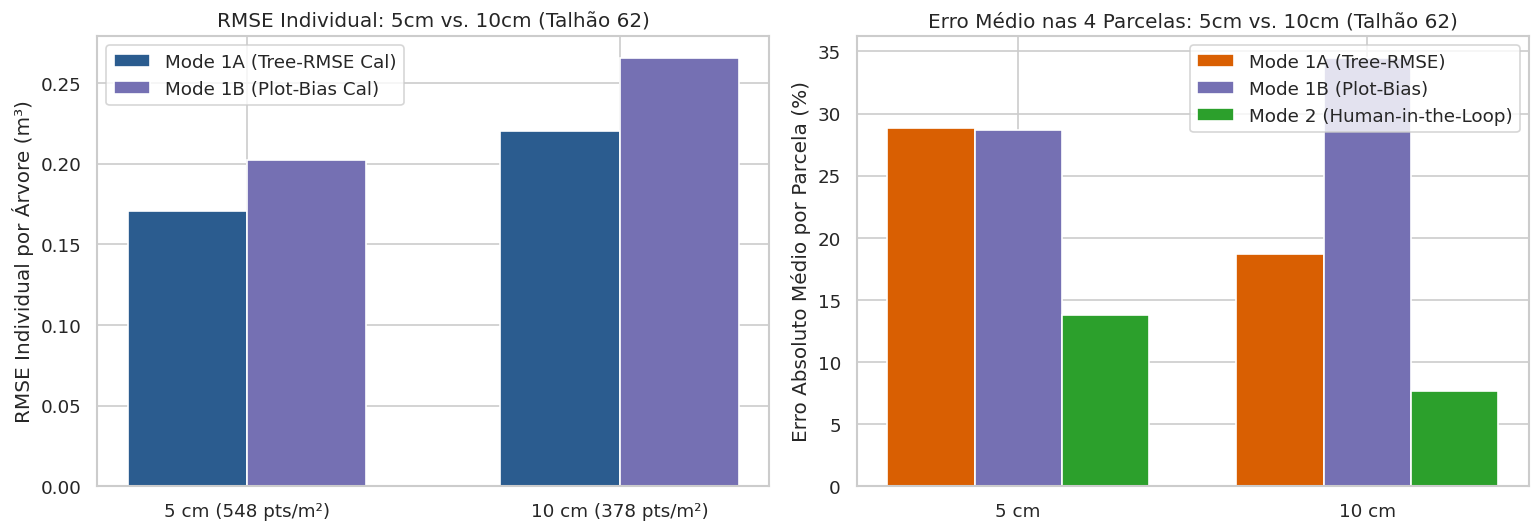

,Resolution,Approx_Point_Density,Matched_Trees,Optimal_Model,Optimal_Bias_Model,Tree_Volume_RMSE_m3,Tree_Volume_Bias_pct,Tree_Volume_RMSE_BiasCal_m3,Tree_Volume_Bias_BiasCal_pct,Mean_Plot_Error_Global_pct,LOPO_Plot_Error_Global_pct,Mean_Plot_Error_BiasCal_pct,LOPO_Plot_Error_BiasCal_pct,Mean_Plot_Error_Human_pct
0,5 cm,548 pts/m²,40,voxel_vs0.07,voxel_vs0.08,0.1709,-22.7,0.2024,10.8,28.8,28.8,28.7,32.3,13.8
1,10 cm,378 pts/m²,38,voxel_vs0.08,voxel_vs0.09,0.2202,-17.6,0.2657,14.1,18.7,21.8,34.5,38.6,7.7


,resolution,plot_id,n_matched,gt_m3_ha,pred_global_m3_ha,err_global_ha_pct,lopo_err_global_ha_pct,pred_bias_cal_m3_ha,err_bias_cal_ha_pct,lopo_err_bias_cal_ha_pct,pred_human_m3_ha,err_human_ha_pct
0,5cm,500,6,218.32,199.72,-8.52,-8.52,281.46,28.92,28.92,210.65,-3.51
1,5cm,503,8,223.43,71.25,-68.11,-68.11,103.62,-53.62,-68.11,191.05,-14.49
2,5cm,508,17,200.72,171.03,-14.79,-14.79,245.71,22.42,22.42,234.30,16.73
3,5cm,509,9,162.69,124.24,-23.64,-23.64,178.65,9.81,9.81,129.69,-20.29
4,10cm,500,6,218.32,217.31,-0.46,-0.46,298.02,36.50,36.50,200.99,-7.94
5,10cm,503,7,223.43,88.73,-60.29,-72.67,124.88,-44.11,-60.29,190.83,-14.59
6,10cm,508,18,200.72,180.53,-10.06,-10.06,250.63,24.86,24.86,209.90,4.57
7,10cm,509,7,162.69,156.32,-3.92,-3.92,215.69,32.58,32.58,168.63,3.65


In [5]:
df_res_sum = pd.read_csv(os.path.join(RESULTS_DIR, 'exp3_resolution_5vs10cm/resolution_comparison_summary.csv'))
df_res_plots = pd.read_csv(os.path.join(RESULTS_DIR, 'exp3_resolution_5vs10cm/plots_resolution_comparison.csv'))
display(df_res_sum)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Painel A: RMSE Individual por Resolução e Critério
x = np.arange(len(df_res_sum))
w = 0.32
axes[0].bar(x - w/2, df_res_sum['Tree_Volume_RMSE_m3'], width=w, label='Mode 1A (Tree-RMSE Cal)', color='#2b5c8f')
axes[0].bar(x + w/2, df_res_sum['Tree_Volume_RMSE_BiasCal_m3'], width=w, label='Mode 1B (Plot-Bias Cal)', color='#7570b3')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_res_sum['Resolution'] + ' (' + df_res_sum['Approx_Point_Density'] + ')')
axes[0].set_ylabel('RMSE Individual por Árvore (m³)')
axes[0].set_title('RMSE Individual: 5cm vs. 10cm (Talhão 62)')
axes[0].legend(frameon=True)

# Painel B: Erro Médio de Parcela (In-Sample e LOPO)
w2 = 0.25
axes[1].bar(x - w2, df_res_sum['Mean_Plot_Error_Global_pct'], width=w2, label='Mode 1A (Tree-RMSE)', color='#d95f02')
axes[1].bar(x, df_res_sum['Mean_Plot_Error_BiasCal_pct'], width=w2, label='Mode 1B (Plot-Bias)', color='#7570b3')
axes[1].bar(x + w2, df_res_sum['Mean_Plot_Error_Human_pct'], width=w2, label='Mode 2 (Human-in-the-Loop)', color='#2ca02c')
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_res_sum['Resolution'])
axes[1].set_ylabel('Erro Absoluto Médio por Parcela (%)')
axes[1].set_title('Erro Médio nas 4 Parcelas: 5cm vs. 10cm (Talhão 62)')
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()
display(df_res_plots.round(2))

### Resultados e Implicações (Experimento 3)
- **Segmentação Nativa em 10cm:** A execução direta do ForestFormer3D nas nuvens de 10cm do Talhão 62 pareou **38 árvores** com o inventário de campo (contra **40 árvores** no voo de 5cm), confirmando que a detecção e o isolamento de fustes permanecem estáveis em 10cm.
- **Deslocamento Ótimo do Tamanho de Voxel:** Em ambos os critérios de calibração, a redução de densidade de `548 pts/m²` (5cm) para `378 pts/m²` (10cm) desloca o tamanho ótimo de voxel em exatamente $+1\text{ cm}$ (`voxel_vs0.07 -> voxel_vs0.08` no Mode 1A, e `voxel_vs0.08 -> voxel_vs0.09` no Mode 1B).
- **Erro em Nível de Parcela:** No voo de 10cm, o modelo `voxel_vs0.08` atingiu erro médio de parcela de **18,7%** (*in-sample*) e **21,8%** (*LOPO*), inferior ao erro médio de parcela observado em 5cm (**28,8%**).

--- 
## Experimento 4: Transferibilidade Entre Talhões em Mesma Resolução (10cm $\leftrightarrow$ 10cm vs. 5cm)

### Objetivo
- Testar a transferência direta de modelos entre os talhões **T37** (`1034,09` árvores/ha, `191,14 m³/ha`) e **T62** (`650,00` árvores/ha, `201,29 m³/ha`) quando ambos estão na mesma resolução de **10cm**, confrontando com a transferência entre resoluções distintas (10cm $\leftrightarrow$ 5cm).

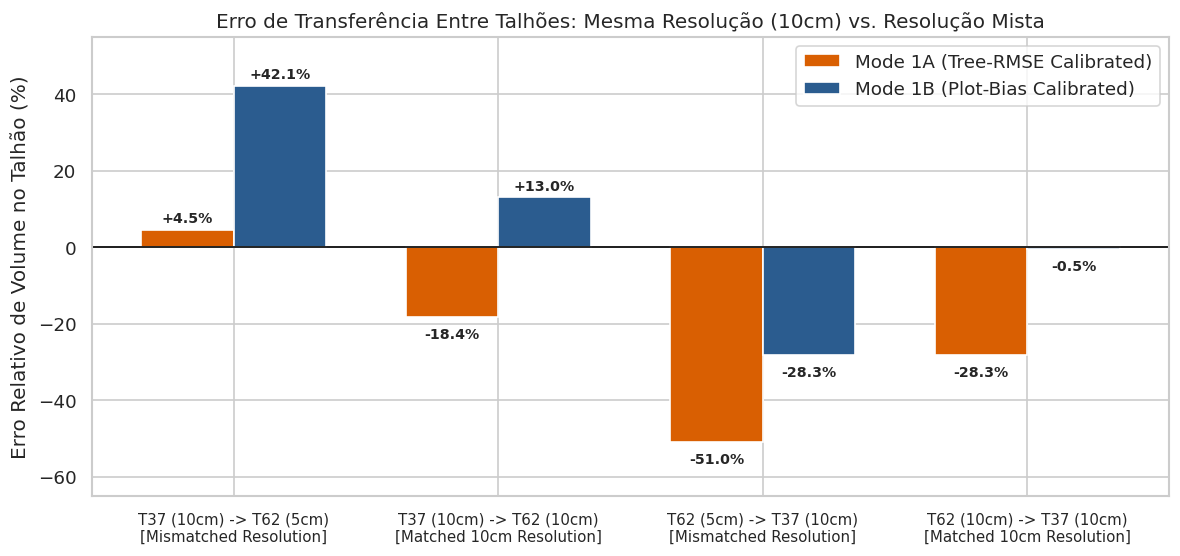

,Experiment,Transfer Direction,Ground Truth (m³/ha),Calibrated Model (Tree-RMSE),Stand Pred Tree-RMSE (m³/ha),Stand Error Tree-RMSE (%),Calibrated Model (Plot-Bias),Stand Pred Plot-Bias (m³/ha),Stand Error Plot-Bias (%)
0,Mismatched Resolution (10cm -> 5cm),T37 (10cm) -> T62 (5cm),201.29,voxel_vs0.08,210.4,4.5,voxel_vs0.09,286.1,42.1
1,Matched 10cm Resolution (10cm -> 10cm),T37 (10cm) -> T62 (10cm),201.29,voxel_vs0.08,164.3,-18.4,voxel_vs0.09,227.5,13.0
2,Mismatched Resolution (5cm -> 10cm),T62 (5cm) -> T37 (10cm),191.14,voxel_vs0.07,93.6,-51.0,voxel_vs0.08,137.1,-28.3
3,Matched 10cm Resolution (10cm -> 10cm),T62 (10cm) -> T37 (10cm),191.14,voxel_vs0.08,137.1,-28.3,voxel_vs0.09,190.3,-0.5


In [6]:
df_exp4 = pd.read_csv(os.path.join(RESULTS_DIR, 'exp4_cross_stand_10cm/cross_stand_resolution_matching_summary.csv'))
cols_show = [
    'Experiment', 'Transfer Direction', 'Ground Truth (m³/ha)',
    'Calibrated Model (Tree-RMSE)', 'Stand Pred Tree-RMSE (m³/ha)', 'Stand Error Tree-RMSE (%)',
    'Calibrated Model (Plot-Bias)', 'Stand Pred Plot-Bias (m³/ha)', 'Stand Error Plot-Bias (%)'
]
display(df_exp4[cols_show])

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(df_exp4))
w = 0.35
b1 = ax.bar(x - w/2, df_exp4['Stand Error Tree-RMSE (%)'], width=w, label='Mode 1A (Tree-RMSE Calibrated)', color='#d95f02')
b2 = ax.bar(x + w/2, df_exp4['Stand Error Plot-Bias (%)'], width=w, label='Mode 1B (Plot-Bias Calibrated)', color='#2b5c8f')
ax.axhline(0, color='black', linewidth=1)

for bar in list(b1) + list(b2):
    val = bar.get_height()
    offset = 2.0 if val >= 0 else -5.5
    ax.text(bar.get_x() + bar.get_width()/2, val + offset, f"{val:+.1f}%", ha='center', fontweight='bold', fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(df_exp4['Transfer Direction'] + '\n[' + df_exp4['Experiment'].str.split(' \(').str[0] + ']', fontsize=9)
ax.set_ylabel('Erro Relativo de Volume no Talhão (%)')
ax.set_ylim(-65, 55)
ax.set_title('Erro de Transferência Entre Talhões: Mesma Resolução (10cm) vs. Resolução Mista')
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

### Resultados e Implicações (Experimento 4)
- **Convergência de Hiperparâmetros na Mesma Resolução (10cm):** Quando avaliados na mesma resolução de 10cm, tanto o Talhão 37 quanto o Talhão 62 selecionam de forma independente os exatos mesmos tamanhos de voxel: **`voxel_vs0.08`** pelo critério de RMSE individual (**Mode 1A**) e **`voxel_vs0.09`** pelo critério de viés (**Mode 1B**).
- **Eliminação do Viés de Resolução Cruzada:**
  - Na direção **T62 $\to$ T37**, transferir os modelos de 5cm (`vs0.07` / `vs0.08`) para a nuvem de 10cm do T37 gera forte subestimação (**-51,0%** no Mode 1A e **-28,3%** no Mode 1B). Ao parear a resolução em **10cm $\to$ 10cm**, o erro sob calibração de viés (`voxel_vs0.09`) cai para **-0,5%** (`190,3 m³/ha` estimado vs. `191,1 m³/ha` oficial).
  - Na direção **T37 $\to$ T62**, transferir o modelo calibrado por viés (`voxel_vs0.09`) de 10cm para 5cm superestima o T62 em **+42,1%** (`286,1 m³/ha`), enquanto na transferência **10cm $\to$ 10cm** o erro cai para **+13,0%** (`227,5 m³/ha`) no Mode 1B e **-18,4%** (`164,3 m³/ha`) no Mode 1A.